# E223 · Self-supervised correspondence discovery

## Stage A · Identity-blind sign crops

3 paired seeds on the E221 split. The archive has no cross-track timestamps. We randomly permute the crops before presenting the matcher with anonymous frozen DINO embeddings. Each update occurs after both halves of its 32-observation block have arrived. Mutual nearest neighbors are accepted above the 90th percentile of cosine similarity among unlabeled random calibration pairs. The Arrival Neighbor control uses nearby positions in this randomized presentation. Both views of every arm have the same raw images. Only the pairing permutation changes. Dataset IDs are joined after inference for the audit, Oracle Track and deliberately corrupted Shuffled controls. The inputs remain dataset-curated sign crops.

| Source | Pairs | Identity precision | Oracle coverage |
| --- | --- | --- | --- |
| Oracle Track | 1908 | 100.0% | 100.0% |
| Automatic Track | 3274 | 43.9% | 75.3% |
| Arrival Neighbor | 3274 | 1.8% | 3.1% |
| Shuffled | 3274 | 0.0% | 0.0% |

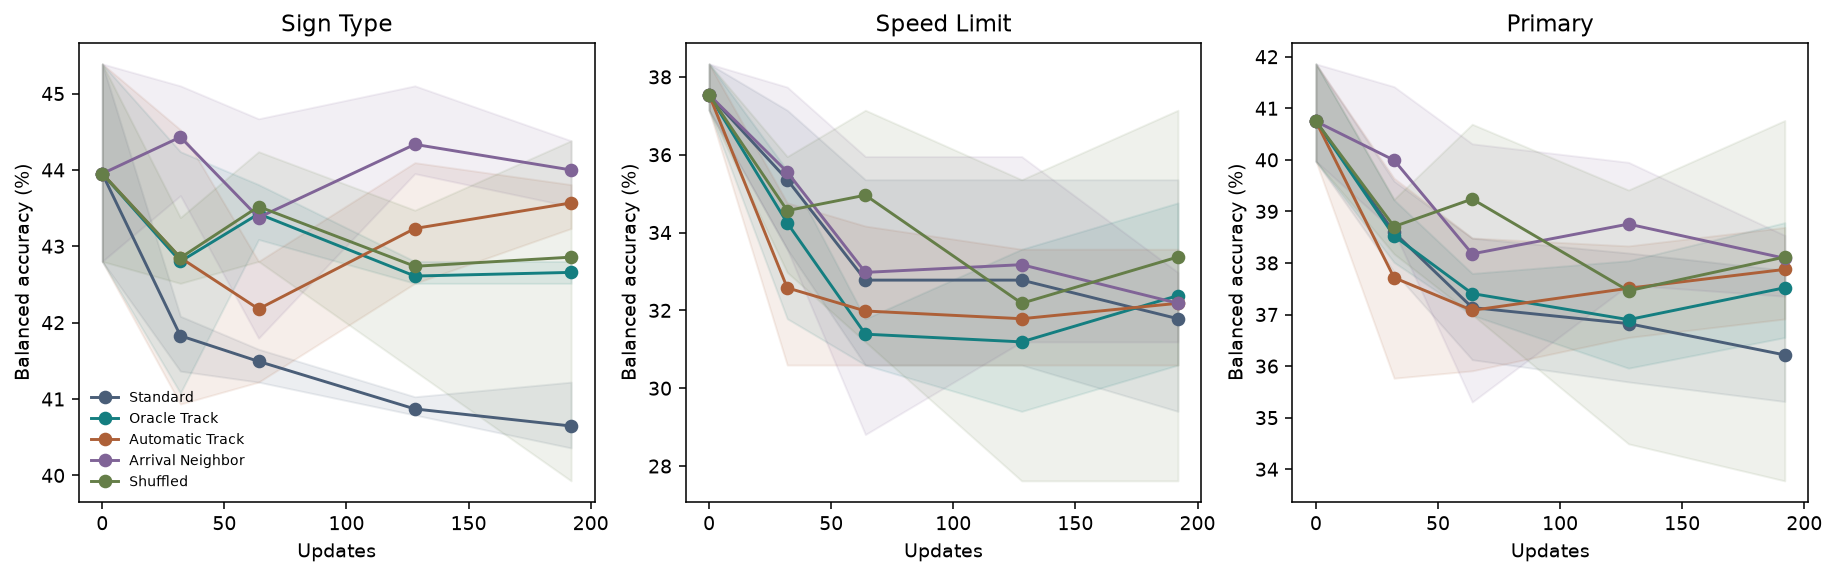

| Policy vs Standard | Readout | Paired endpoint gains (pp) |
| --- | --- | --- |
| Oracle Track | sign_type | +1.44, +2.16, +2.44 |
| Oracle Track | speed_limit | +2.38, +0.00, -0.60 |
| Oracle Track | primary | +1.91, +1.08, +0.92 |
| Automatic Track | sign_type | +2.01, +3.45, +3.30 |
| Automatic Track | speed_limit | +1.19, +2.98, -2.98 |
| Automatic Track | primary | +1.60, +3.21, +0.16 |
| Arrival Neighbor | sign_type | +2.30, +4.02, +3.74 |
| Arrival Neighbor | speed_limit | +1.79, +1.79, -2.38 |
| Arrival Neighbor | primary | +2.04, +2.90, +0.68 |
| Shuffled | sign_type | +3.16, -0.43, +3.90 |
| Shuffled | speed_limit | +7.74, -2.98, +0.00 |
| Shuffled | primary | +5.45, -1.70, +1.95 |

| Readout | Automatic recovery of positive Oracle gain |
| --- | --- |
| sign_type | 145.2% |
| speed_limit | 66.7% |
| primary | 127.3% |

## Stage B · Raw chronological BDD regions

A frozen DINO feature encoder and bidirectional Farnebäck flow match each current crop to a crop 2–6 observed frames earlier. The confidence multiplies token appearance agreement, forward/backward cycle consistency, and visibility checks based on photometric error and frame bounds. The threshold is fixed on eight unlabeled development clips. Four policies use the same chronological clips, anchor regions, augmentation seeds and update count. Flow uniform weighs accepted pairs equally. Flow weighted uses the confidence product to weight symmetric stop-gradient SimSiam. Shuffled weighted permutes targets across clips. An empty match batch uses same-image positives. BDD labels enter only in independent frozen-feature probes. [OpenCV flow convention](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html)

On held-out frames with known synthetic shifts and occlusions, the matcher accepted **22/36** visible regions. The accepted median coordinate error was **0.00 px** against **11.40 px** for stationary coordinates. It rejected **12/12** synthetic occlusions. Real-video object identities were unavailable for this pilot. The gallery shows accepted and rejected raw matches for visual review.

Accepted region share by seed · 70.0%, 67.3%, 68.5%

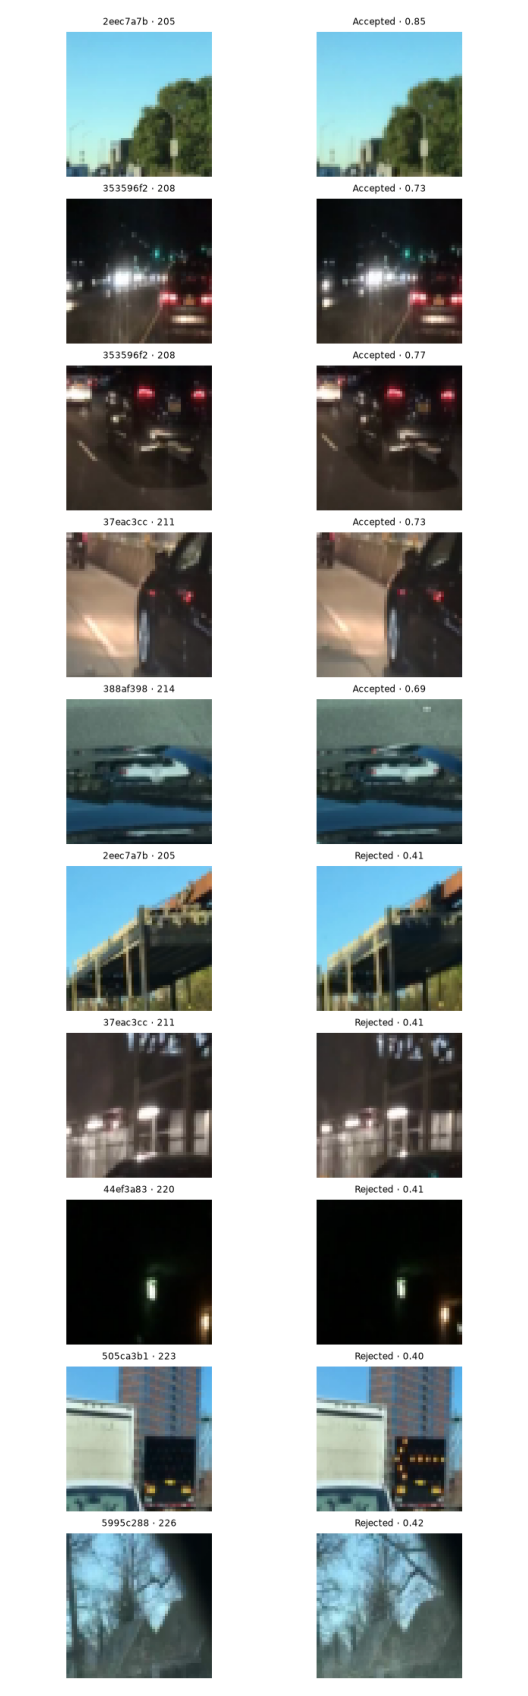

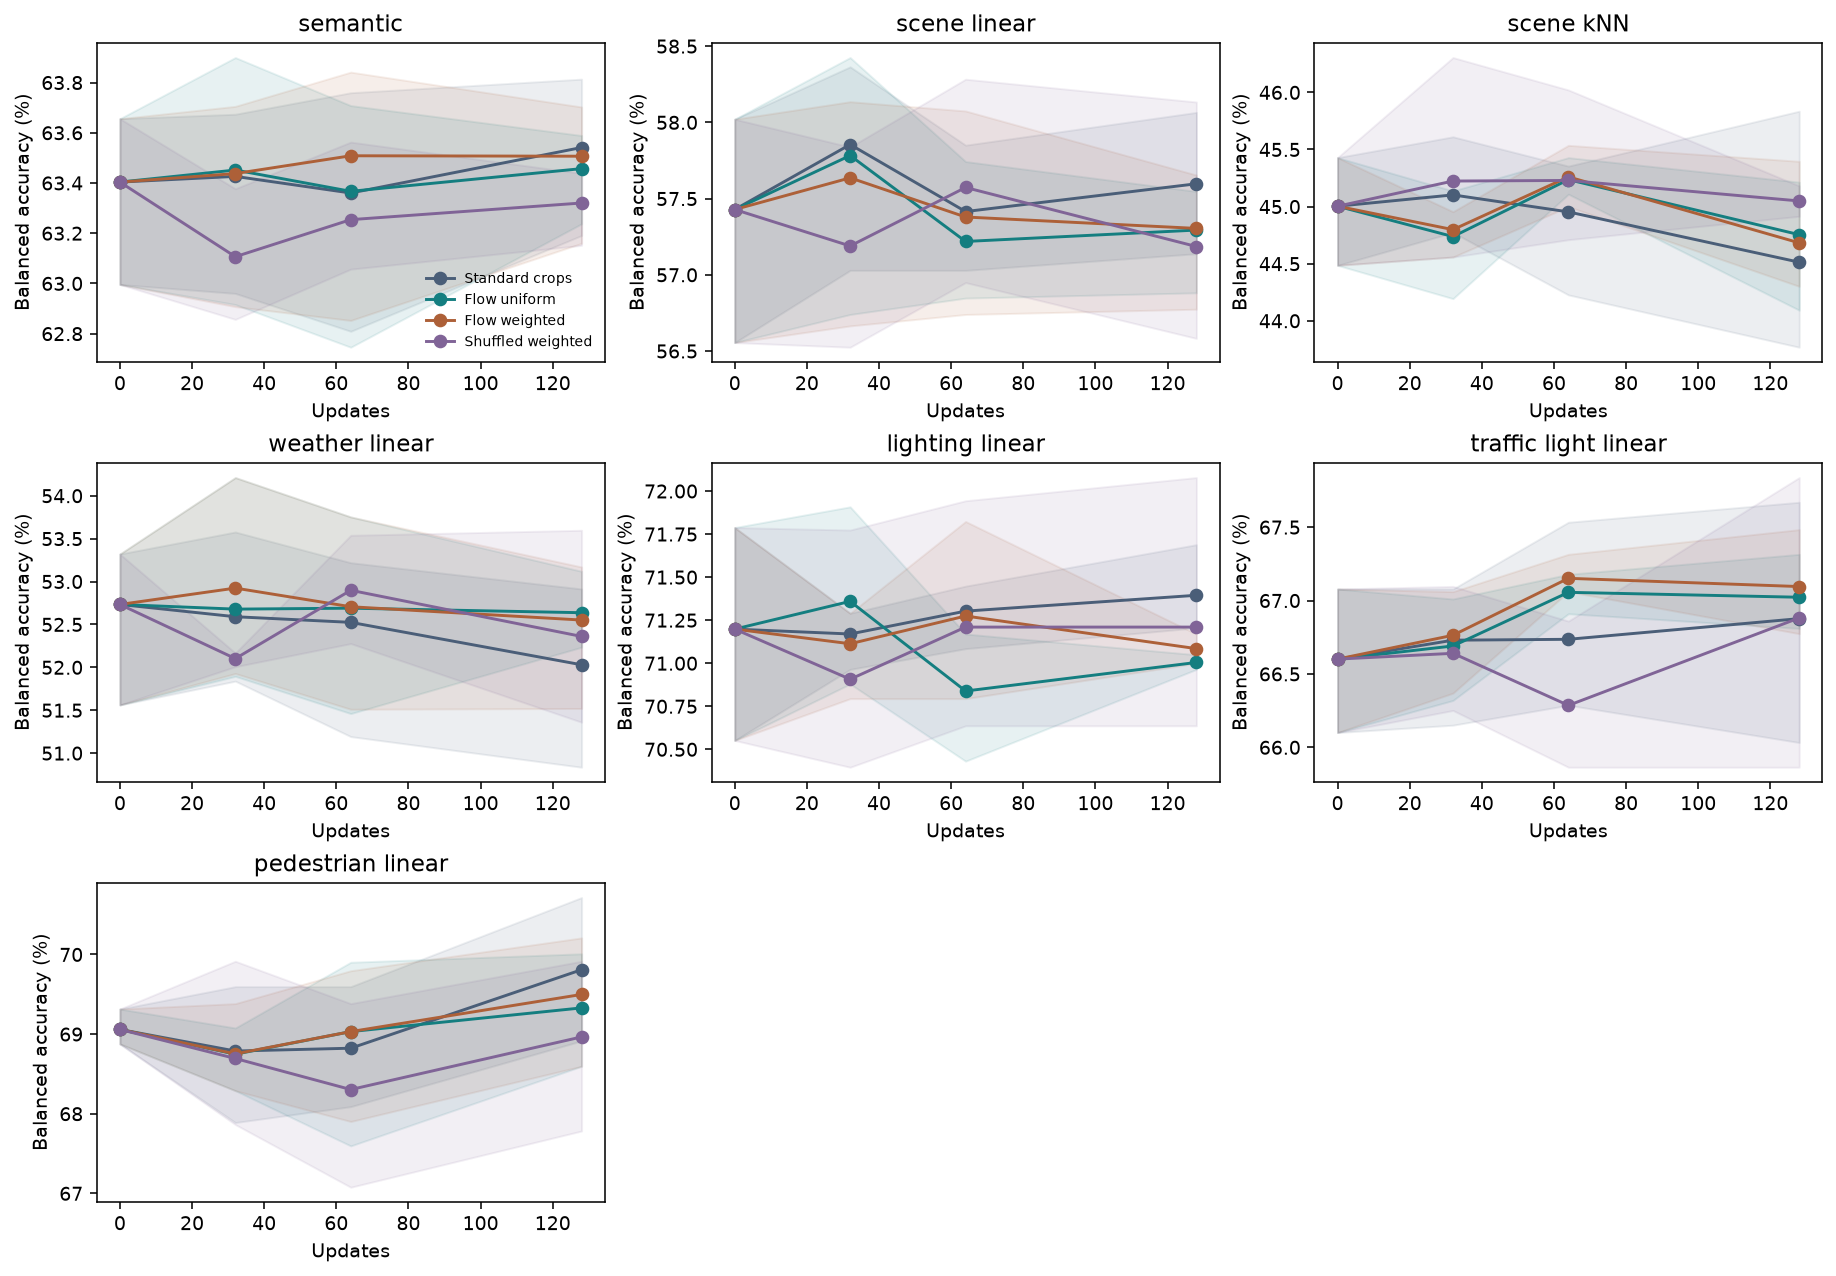

| Arm vs Standard crops | Final paired mean-probe differences (pp) |
| --- | --- |
| Flow uniform | -0.03, +0.05, -0.27 |
| Flow weighted | +0.04, -0.03, -0.11 |
| Shuffled weighted | -0.47, +0.25, -0.44 |